In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

print("BDSRAIE Results Analysis")

BDSRAIE Results Analysis


In [2]:
ROOT = Path.cwd()

if not (ROOT / "results").exists():
    ROOT = ROOT.parent

RESULTS = ROOT / "results"

files = {
    "write": "write_benchmark.csv",
    "query": "query_benchmark.csv",
    "write_energy": "write_energy.csv",
    "query_energy": "query_energy.csv",
    "write_summary": "write_summary.csv",
    "query_summary": "query_summary.csv",
    "petabyte": "petabyte_extrapolation.csv"
}

data = {
    name: pd.read_csv(RESULTS / filename, keep_default_na=False)
    for name, filename in files.items()
}

for name, df in data.items():
    print(f"{name}: {len(df)} rows")

print("\nAll benchmark results loaded successfully!")

write: 30 rows
query: 120 rows
write_energy: 30 rows
query_energy: 120 rows
write_summary: 30 rows
query_summary: 30 rows
petabyte: 30 rows

All benchmark results loaded successfully!


In [3]:
write_df = data["write"]
query_df = data["query"]

print("Dataset configurations:", len(write_df))
print("Query measurements:", len(query_df))

print("\nFormats tested:")
print(write_df.groupby("format").size())

print("\nCompression codecs:")
print(sorted(write_df["codec"].unique()))

print("\nPartitioning strategies:")
print(sorted(write_df["partitioning"].unique()))

Dataset configurations: 30
Query measurements: 120

Formats tested:
format
avro        9
orc         9
parquet    12
dtype: int64

Compression codecs:
['deflate', 'gzip', 'none', 'null', 'snappy', 'uncompressed', 'zlib', 'zstd']

Partitioning strategies:
['by_date', 'by_date_zone', 'none']


## 3. Storage Analysis

This section compares the storage requirements of Parquet, ORC, and Avro
under different compression codecs and partitioning strategies.

The objective is to identify which configurations minimize storage
consumption while considering the trade-offs introduced by partitioning.

Average storage size by format (MB):


format
parquet   113.0400
orc       146.2244
avro      325.9589
Name: size_mb, dtype: float64

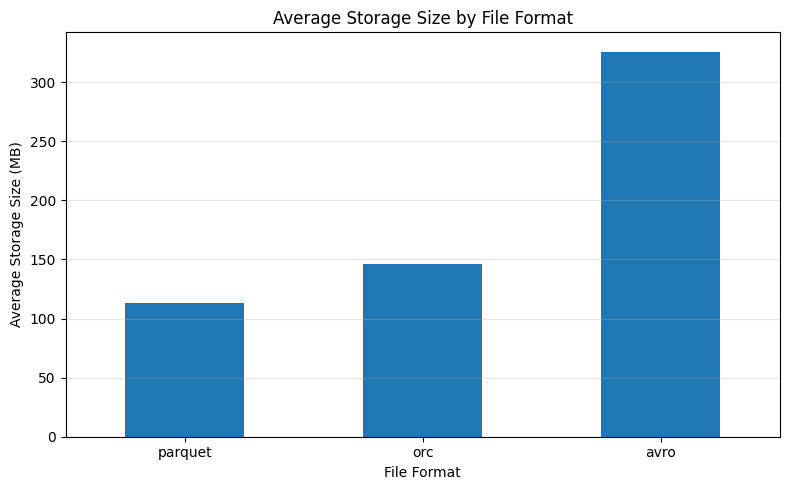

In [4]:
# Average storage size by file format

storage_by_format = (
    write_df.groupby("format")["size_mb"]
    .mean()
    .sort_values()
)

print("Average storage size by format (MB):")
display(storage_by_format)

plt.figure(figsize=(8, 5))

storage_by_format.plot(kind="bar")

plt.title("Average Storage Size by File Format")
plt.xlabel("File Format")
plt.ylabel("Average Storage Size (MB)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Storage size by format and partitioning:


partitioning,by_date,by_date_zone,none
format,,,
avro,327.6133,322.6100,327.6533
orc,146.0867,146.8100,145.7767
parquet,103.8825,137.2850,97.9525


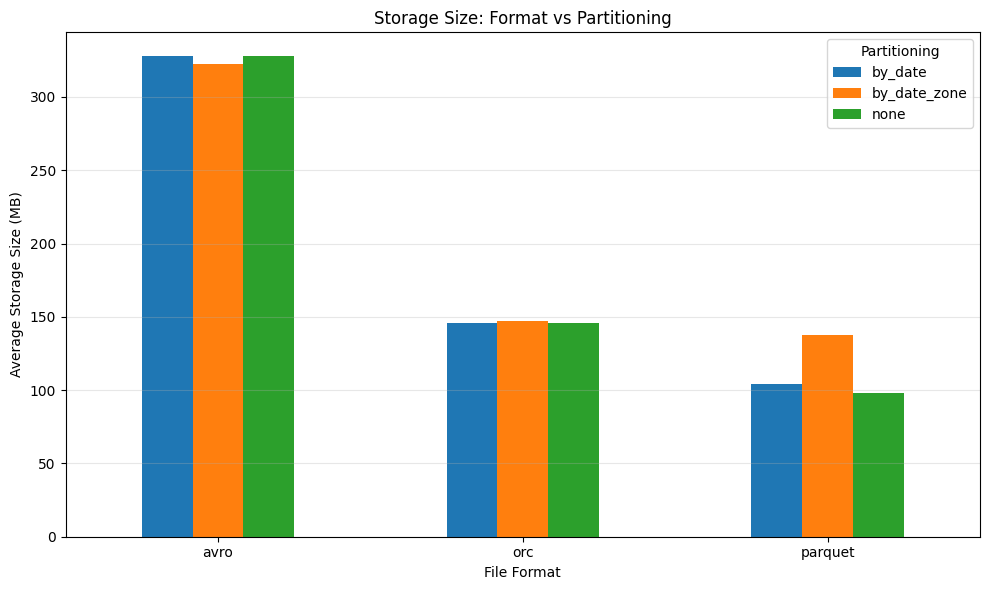

In [5]:
# Average storage size by format and partitioning

storage_partition = write_df.pivot_table(
    index="format",
    columns="partitioning",
    values="size_mb",
    aggfunc="mean"
)

print("Storage size by format and partitioning:")
display(storage_partition)

storage_partition.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Storage Size: Format vs Partitioning")
plt.xlabel("File Format")
plt.ylabel("Average Storage Size (MB)")
plt.xticks(rotation=0)
plt.legend(title="Partitioning")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Compression Analysis

This section evaluates the impact of compression codecs on storage size.

We compare compression methods across Parquet, ORC, and Avro to understand
their effectiveness and the associated storage trade-offs.

format,avro,orc,parquet
codec,,,
deflate,144.2833,NaN,NaN
gzip,NaN,NaN,97.6600
none,NaN,NaN,131.8000
null,609.5667,NaN,NaN
snappy,224.0267,NaN,118.3267
uncompressed,NaN,288.3267,NaN
zlib,NaN,73.2467,NaN
zstd,NaN,77.1000,104.3733


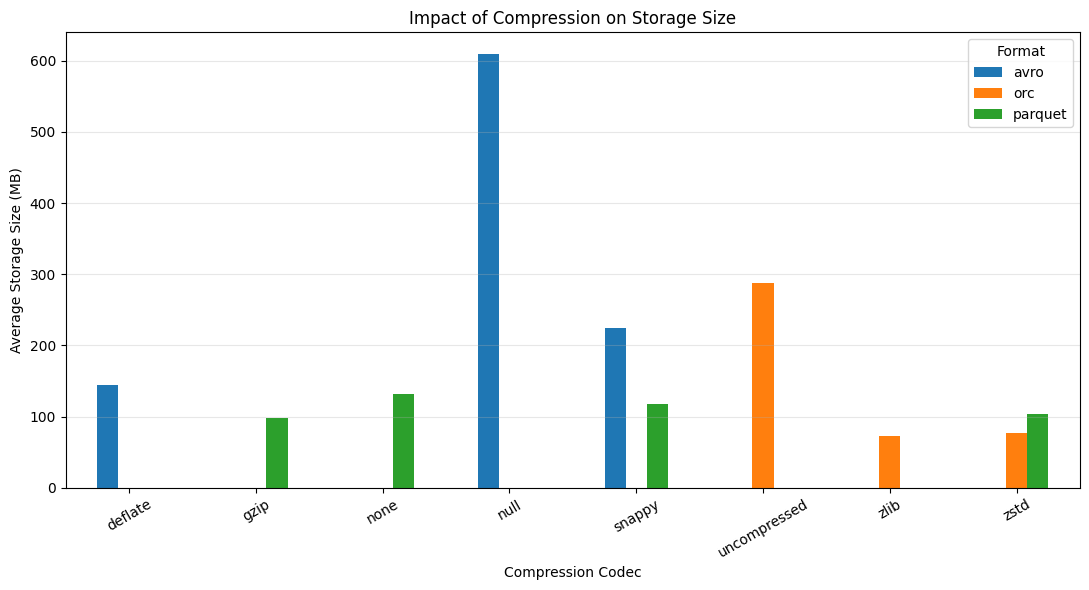

In [6]:
# Average storage size by format and codec

compression_results = write_df.pivot_table(
    index="codec",
    columns="format",
    values="size_mb",
    aggfunc="mean"
)

display(compression_results)

compression_results.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Impact of Compression on Storage Size")
plt.xlabel("Compression Codec")
plt.ylabel("Average Storage Size (MB)")
plt.xticks(rotation=30)
plt.legend(title="Format")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Query Performance Analysis

This section evaluates the query execution performance of Parquet, ORC,
and Avro under different compression and partitioning configurations.

Four workloads are considered:

1. Point Lookup
2. Full Scan Aggregation
3. Wide Scan
4. Range Filter

Wall-clock execution time and CPU execution time are used as performance
metrics. Lower execution time indicates better query performance.

Average query execution time (seconds):


format
parquet    0.0788
orc        0.4663
avro      22.1315
Name: wall_seconds, dtype: float64

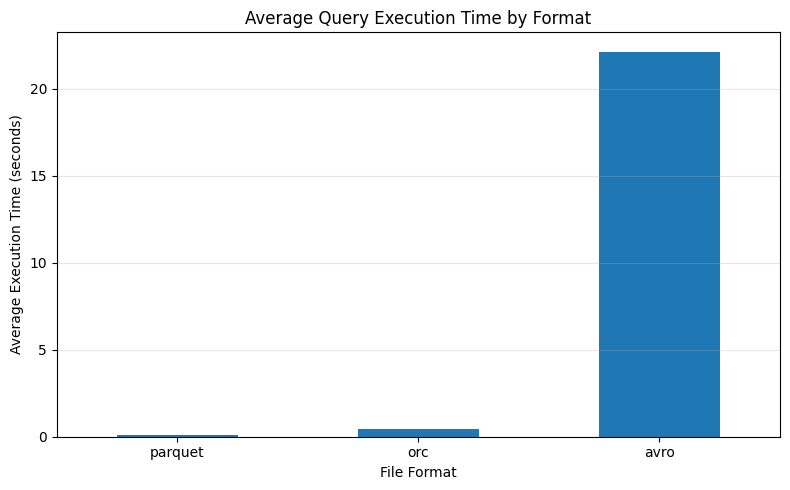

In [7]:
# Average query execution time by file format

query_by_format = (
    query_df.groupby("format")["wall_seconds"]
    .mean()
    .sort_values()
)

print("Average query execution time (seconds):")
display(query_by_format)

plt.figure(figsize=(8, 5))

query_by_format.plot(kind="bar")

plt.title("Average Query Execution Time by Format")
plt.xlabel("File Format")
plt.ylabel("Average Execution Time (seconds)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Query performance comparison:


format,avro,orc,parquet
query,,,
full_scan_agg,32.4458,0.7142,0.1337
point_lookup,10.8539,0.2355,0.0244
range_filter,12.8074,0.2522,0.0289
wide_scan,32.4190,0.6633,0.1284


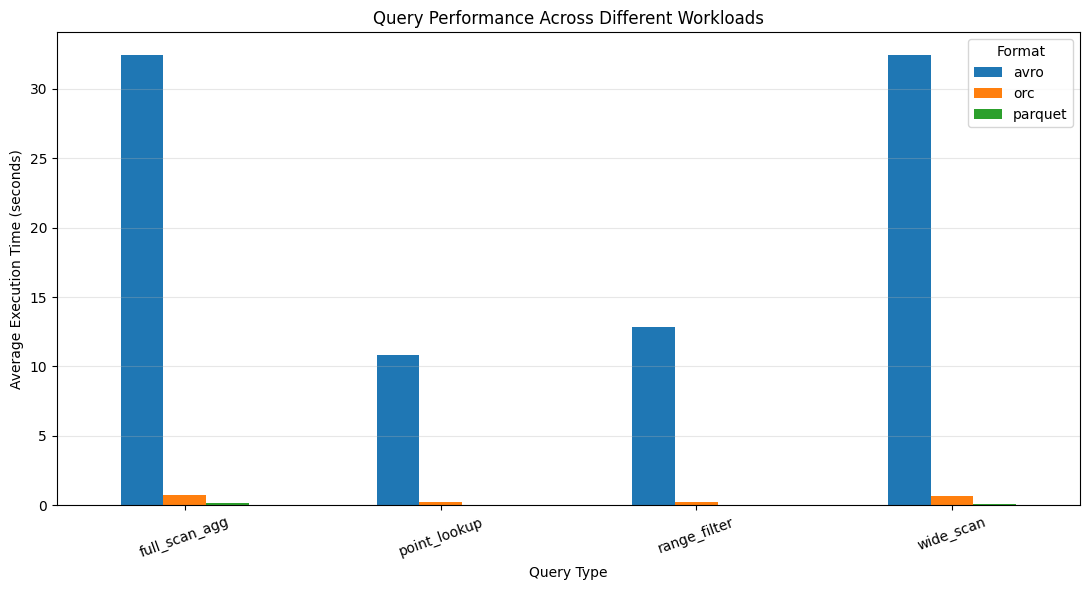

In [8]:
# Average execution time for each query workload and format

query_comparison = query_df.pivot_table(
    index="query",
    columns="format",
    values="wall_seconds",
    aggfunc="mean"
)

print("Query performance comparison:")
display(query_comparison)

query_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Query Performance Across Different Workloads")
plt.xlabel("Query Type")
plt.ylabel("Average Execution Time (seconds)")
plt.xticks(rotation=20)
plt.legend(title="Format")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Query time by partitioning strategy:


query,full_scan_agg,point_lookup,range_filter,wide_scan
partitioning,,,,
by_date,9.9917,0.0901,0.9647,9.9608
by_date_zone,10.2525,0.0463,0.9917,10.1647
none,9.7602,9.8733,9.8318,9.8026


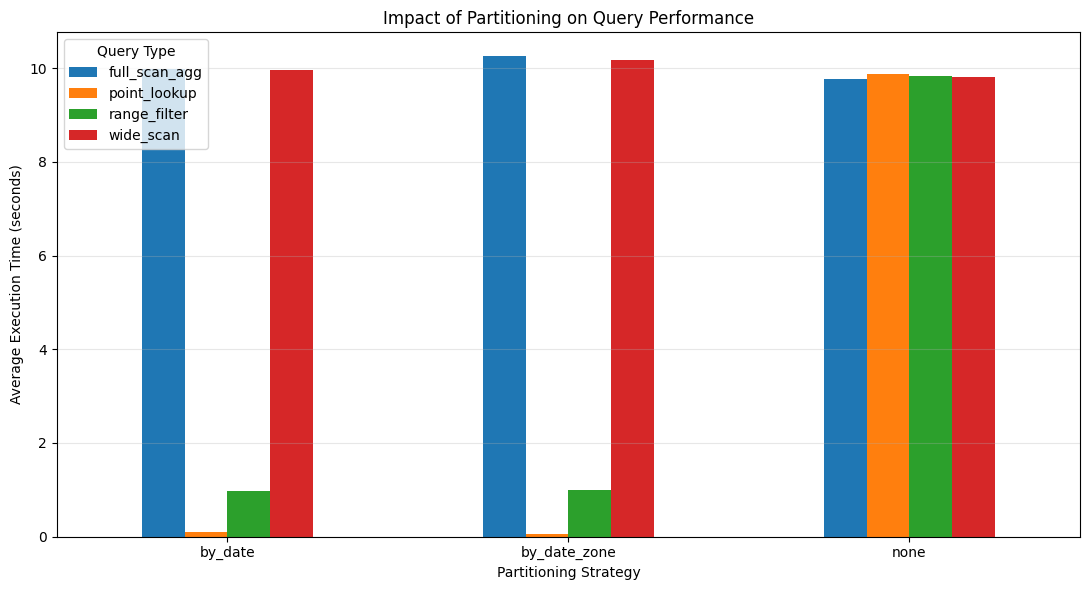

In [9]:
# Compare query performance across partitioning strategies

partition_comparison = query_df.pivot_table(
    index="partitioning",
    columns="query",
    values="wall_seconds",
    aggfunc="mean"
)

print("Query time by partitioning strategy:")
display(partition_comparison)

partition_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Impact of Partitioning on Query Performance")
plt.xlabel("Partitioning Strategy")
plt.ylabel("Average Execution Time (seconds)")
plt.xticks(rotation=0)
plt.legend(title="Query Type")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Find the fastest configuration for each query type

best_queries = (
    query_df.sort_values("wall_seconds")
    .groupby("query")
    .first()
    .reset_index()
)

print("Best configuration for each query workload:")

display(
    best_queries[
        ["query", "format", "codec", "partitioning", "wall_seconds"]
    ]
)

Best configuration for each query workload:


,query,format,codec,partitioning,wall_seconds
0,full_scan_agg,parquet,snappy,none,0.0527
1,point_lookup,parquet,zstd,by_date,0.0053
2,range_filter,parquet,none,by_date,0.0074
3,wide_scan,parquet,snappy,none,0.0402


## 6. Energy Consumption Analysis

This section evaluates the estimated energy consumption of different
file formats, compression codecs and partitioning strategies.

Two stages are considered:

1. Write Energy: Energy consumed while converting and storing the dataset.
2. Query Energy: Energy consumed while executing analytical workloads.

Energy consumption is measured in Watt-hours (Wh).

Lower energy consumption indicates better energy efficiency.

In [12]:
import pandas as pd
import os

# Check current working directory
print("Current directory:", os.getcwd())

# Locate results folder
if os.path.isdir("results"):
    results_path = "results/"
elif os.path.isdir("../results"):
    results_path = "../results/"
else:
    raise FileNotFoundError("Could not locate the results folder.")

print("Using results folder:", results_path)

# Load energy benchmark results
write_energy_df = pd.read_csv(results_path + "write_energy.csv")
query_energy_df = pd.read_csv(results_path + "query_energy.csv")

print("\nWrite energy records:", len(write_energy_df))
print("Query energy records:", len(query_energy_df))

print("\nWrite energy columns:")
print(write_energy_df.columns.tolist())

print("\nQuery energy columns:")
print(query_energy_df.columns.tolist())

display(write_energy_df.head())
display(query_energy_df.head())

Current directory: /Users/sirisanikop/Desktop/BDSRAIE/notebooks
Using results folder: ../results/

Write energy records: 30
Query energy records: 120

Write energy columns:
['format', 'codec', 'partitioning', 'write_seconds', 'size_bytes', 'size_mb', 'file_count', 'path', 'size_gb', 'write_energy_joules', 'write_energy_wh']

Query energy columns:
['format', 'codec', 'partitioning', 'query', 'wall_seconds', 'cpu_seconds', 'size_gb', 'query_energy_joules', 'query_energy_wh']


,format,codec,partitioning,write_seconds,size_bytes,size_mb,file_count,path,size_gb,write_energy_joules,write_energy_wh
0,parquet,snappy,none,0.7970,102545209,102.5500,1,parquet_snappy_none.parquet,0.1025,12.0081,0.0033
1,parquet,snappy,by_date,0.3890,109260820,109.2600,115,parquet_snappy_by_date,0.1093,5.8626,0.0016
2,parquet,snappy,by_date_zone,1.1760,143171721,143.1700,1679,parquet_snappy_by_date_zone,0.1432,17.7494,0.0049
3,parquet,gzip,none,5.6880,80602505,80.6000,1,parquet_gzip_none.parquet,0.0806,85.6180,0.0238
4,parquet,gzip,by_date,1.1410,90393096,90.3900,115,parquet_gzip_by_date,0.0904,17.1820,0.0048


,format,codec,partitioning,query,wall_seconds,cpu_seconds,size_gb,query_energy_joules,query_energy_wh
0,parquet,snappy,none,point_lookup,0.0340,0.0755,0.1025,1.1348,0.0003
1,parquet,snappy,none,full_scan_agg,0.0527,0.0615,0.1025,0.9260,0.0003
2,parquet,snappy,none,wide_scan,0.0402,0.1493,0.1025,2.2422,0.0006
3,parquet,snappy,none,range_filter,0.0265,0.1298,0.1025,1.9488,0.0005
4,parquet,snappy,by_date,point_lookup,0.0056,0.0040,0.1093,0.0604,0.0000


Average write energy (Wh):


format
parquet   0.0061
orc       0.0133
avro      0.1925
Name: write_energy_wh, dtype: float64

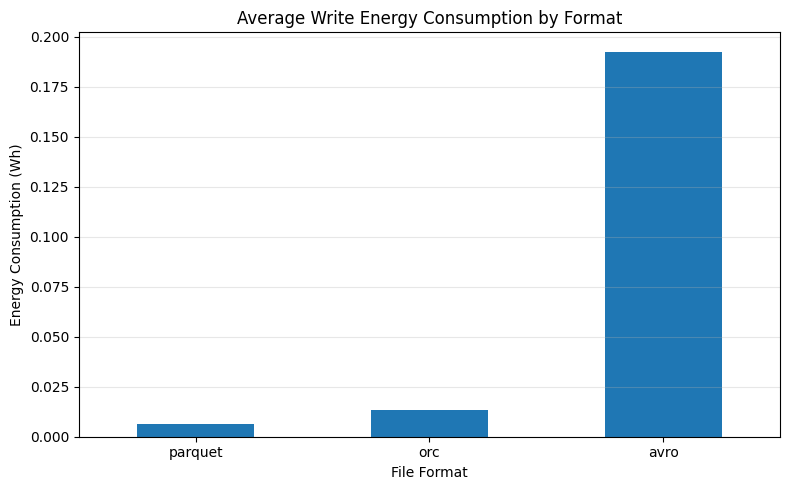

In [13]:
# Average write energy consumption by format

write_energy_comparison = (
    write_energy_df.groupby("format")["write_energy_wh"]
    .mean()
    .sort_values()
)

print("Average write energy (Wh):")
display(write_energy_comparison)

plt.figure(figsize=(8, 5))

write_energy_comparison.plot(kind="bar")

plt.title("Average Write Energy Consumption by Format")
plt.xlabel("File Format")
plt.ylabel("Energy Consumption (Wh)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Average query energy (Wh):


format
parquet   0.0011
orc       0.0020
avro      0.0933
Name: query_energy_wh, dtype: float64

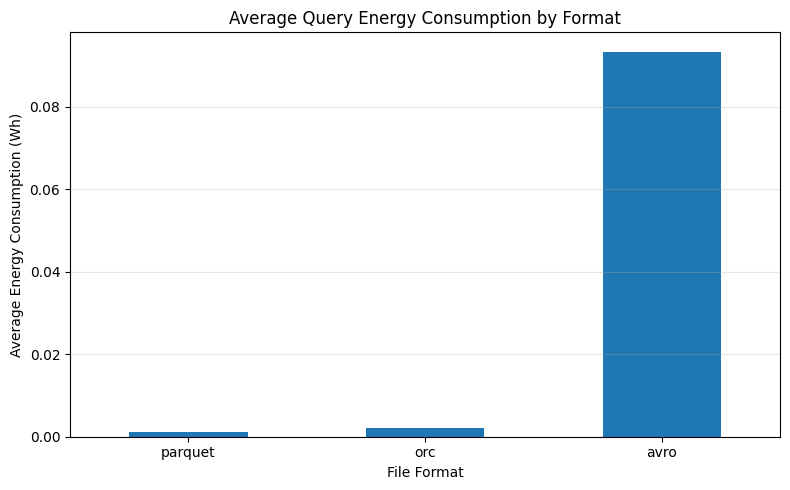

In [14]:
# Average query energy consumption by format

query_energy_comparison = (
    query_energy_df.groupby("format")["query_energy_wh"]
    .mean()
    .sort_values()
)

print("Average query energy (Wh):")
display(query_energy_comparison)

plt.figure(figsize=(8, 5))

query_energy_comparison.plot(kind="bar")

plt.title("Average Query Energy Consumption by Format")
plt.xlabel("File Format")
plt.ylabel("Average Energy Consumption (Wh)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Energy consumption by workload:


format,avro,orc,parquet
query,,,
full_scan_agg,0.1368,0.0025,0.0011
point_lookup,0.0458,0.0007,0.0002
range_filter,0.0541,0.0013,0.0006
wide_scan,0.1366,0.0035,0.0023


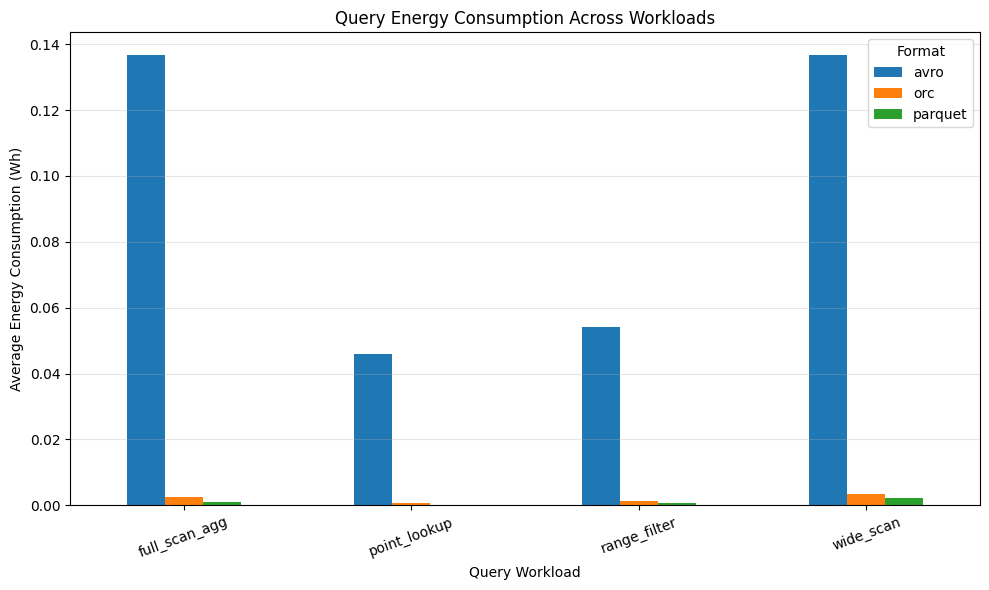

In [15]:
# Compare energy consumption across different query workloads

energy_workload = query_energy_df.pivot_table(
    index="query",
    columns="format",
    values="query_energy_wh",
    aggfunc="mean"
)

print("Energy consumption by workload:")
display(energy_workload)

energy_workload.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Query Energy Consumption Across Workloads")
plt.xlabel("Query Workload")
plt.ylabel("Average Energy Consumption (Wh)")
plt.xticks(rotation=20)
plt.legend(title="Format")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Query energy by partitioning:


query,full_scan_agg,point_lookup,range_filter,wide_scan
partitioning,,,,
by_date,0.0421,0.0004,0.0042,0.0427
by_date_zone,0.0434,0.0002,0.0045,0.0443
none,0.0413,0.0416,0.0419,0.0418


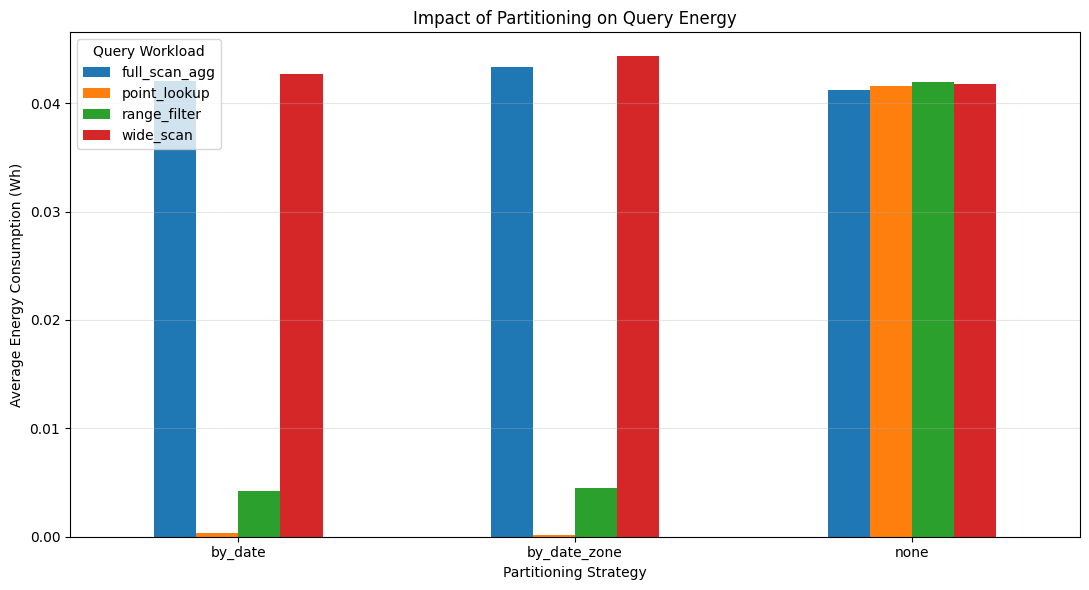

In [16]:
# Compare query energy across partitioning strategies

partition_energy = query_energy_df.pivot_table(
    index="partitioning",
    columns="query",
    values="query_energy_wh",
    aggfunc="mean"
)

print("Query energy by partitioning:")
display(partition_energy)

partition_energy.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Impact of Partitioning on Query Energy")
plt.xlabel("Partitioning Strategy")
plt.ylabel("Average Energy Consumption (Wh)")
plt.xticks(rotation=0)
plt.legend(title="Query Workload")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Lowest-energy configuration for each query workload

best_energy_configs = (
    query_energy_df.sort_values("query_energy_wh")
    .groupby("query")
    .first()
    .reset_index()
)

print("Most energy-efficient configuration per workload:")

display(
    best_energy_configs[
        ["query", "format", "codec", "partitioning", "query_energy_wh"]
    ]
)

Most energy-efficient configuration per workload:


,query,format,codec,partitioning,query_energy_wh
0,full_scan_agg,parquet,snappy,none,0.0003
1,point_lookup,parquet,none,by_date,0.0000
2,range_filter,parquet,none,by_date,0.0002
3,wide_scan,parquet,none,none,0.0005


# 7. Petabyte-Scale Extrapolation

This section estimates how the observed storage and energy costs
would scale when handling petabyte-scale datasets.

The objective is to understand the practical implications of
choosing different file formats, compression codecs and
partitioning strategies for large data platforms.

In [18]:
# Load petabyte-scale projections

petabyte_df = pd.read_csv("../results/petabyte_extrapolation.csv")

print("Petabyte-scale projections:")
display(
    petabyte_df.sort_values(
        "projected_write_energy_kwh_at_pb_scale"
    ).head(10)
)

# Best configuration for storage
best_storage = petabyte_df.loc[
    petabyte_df["projected_size_tb_at_pb_scale"].idxmin()
]

# Best configuration for write energy
best_energy = petabyte_df.loc[
    petabyte_df["projected_write_energy_kwh_at_pb_scale"].idxmin()
]

print("\nBest storage configuration:")
display(best_storage)

print("\nBest write-energy configuration:")
display(best_energy)

Petabyte-scale projections:


,format,codec,partitioning,sample_size_mb,projected_size_tb_at_pb_scale,projected_write_energy_kwh_at_pb_scale
9,parquet,zstd,by_date,97.5200,97.5000,1.4000
12,parquet,none,by_date,118.3600,118.4000,1.4000
11,parquet,snappy,by_date,109.2600,109.3000,1.6000
14,parquet,none,none,123.9400,123.9000,2.9000
10,parquet,snappy,none,102.5500,102.5000,3.3000
7,parquet,zstd,none,84.7200,84.7000,3.6000
24,orc,uncompressed,none,287.6900,287.7000,4.6000
8,parquet,gzip,by_date,90.3900,90.4000,4.8000
17,parquet,snappy,by_date_zone,143.1700,143.2000,4.9000
20,parquet,none,by_date_zone,153.1000,153.1000,5.2000



Best storage configuration:


format                                             orc
codec                                             zlib
partitioning                              by_date_zone
sample_size_mb                                 73.0900
projected_size_tb_at_pb_scale                  73.1000
projected_write_energy_kwh_at_pb_scale         25.6000
Name: 0, dtype: object


Best write-energy configuration:


format                                    parquet
codec                                        zstd
partitioning                              by_date
sample_size_mb                            97.5200
projected_size_tb_at_pb_scale             97.5000
projected_write_energy_kwh_at_pb_scale     1.4000
Name: 9, dtype: object

# 8. Final Conclusions and Recommendations

## Key Findings

1. **Storage Efficiency:** Parquet achieved the lowest average storage size (113.04 MB), followed by ORC (146.22 MB) and Avro (325.96 MB).

2. **Query Performance:** Parquet demonstrated the best overall query performance, with an average execution time of approximately 0.079 seconds. ORC averaged 0.466 seconds, while Avro was significantly slower.

3. **Compression:** Compression codecs had different effects on storage size depending on the file format. The effectiveness of compression must be evaluated alongside write and query performance.

4. **Partitioning:** Date-based and date-zone partitioning significantly improved point lookup performance compared with unpartitioned datasets. However, partitioning did not provide the same benefit for full-scan workloads.

5. **Energy Consumption:** Parquet generally demonstrated lower estimated energy consumption for the tested query workloads. Energy efficiency depends on the selected format, codec and partitioning strategy.

## Recommendations

| Workload | Recommended approach |
|---|---|
| Storage-efficient workloads | Parquet with ZSTD or Snappy |
| Query-intensive workloads | Parquet with suitable date-based partitioning |
| Point lookup workloads | Parquet with date-zone partitioning |
| Full-scan workloads | Parquet with minimal partitioning |
| Large-scale data systems | Parquet with workload-specific compression and partitioning |

## Overall Conclusion

The experiments indicate that Parquet provides the best overall balance of storage efficiency, query performance and estimated energy consumption among the three evaluated formats.

ORC remains a reasonable alternative for workloads where its compression and analytical capabilities are beneficial. Avro may be more suitable for row-oriented data serialization and data exchange rather than the analytical workloads evaluated in this experiment.

The final choice of storage format should depend on workload characteristics rather than storage size alone.

**Note:** Petabyte-scale results are extrapolations from the benchmark dataset and should be treated as estimates rather than actual production measurements.